<a href="https://colab.research.google.com/github/paty3090/Atividade-do-Curso-Deep-Learning/blob/main/atividade_pratica_01_sklearn_pytorch_basics_patricia_alcantara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade prática — do ML clássico a uma MLP

**Semanas 01 e 02 · Dataset Digits · Scikit-learn + PyTorch**

Nesta atividade você irá carregar e inspecionar dados, separar treino e teste, normalizar sem vazamento, treinar uma regressão logística e uma rede MLP, calcular métricas e analisar erros.

**Regras para a correção automática**

- Não altere nomes, parâmetros ou retornos das funções.
- Não use o conjunto de teste para ajustar o normalizador ou treinar modelos.
- Mantenha `random_state=42` e as sementes indicadas.
- CPU é suficiente. Em *Ambiente de execução*, selecione **Executar tudo** antes de entregar.
- A pontuação total é 10,0. Consulte a tabela no fim do notebook.

In [184]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## Exercício 1 — Carregamento e exploração

Carregue o dataset `Digits`. Retorne `X` como matriz `(n_amostras, 64)` e `y` como vetor de inteiros. Depois visualize algumas imagens: cada linha possui os 64 pixels de uma imagem 8×8.

In [185]:
def load_digits_data():
    # Carrega o dataset Digits do scikit-learn
    digits = load_digits()
    X = digits.data
    y = digits.target
    return X, y

X: (1797, 64) y: (1797,) classes: [0 1 2 3 4 5 6 7 8 9]


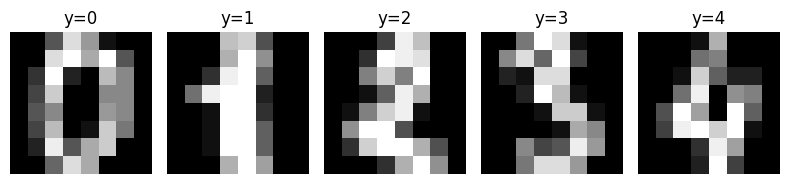

In [186]:
X, y = load_digits_data()
print("X:", X.shape, "y:", y.shape, "classes:", np.unique(y))

fig, axes = plt.subplots(1, 5, figsize=(8, 2))
for ax, image, label in zip(axes, X[:5], y[:5]):
    ax.imshow(image.reshape(8, 8), cmap="gray")
    ax.set_title(f"y={label}")
    ax.axis("off")
plt.tight_layout()

## Exercício 2 — Divisão estratificada

Separe 80% para treino e 20% para teste, com estratificação por classe e `random_state=42`. (Dica train_test_split)

In [187]:
def split_data(X, y):
    # Divide em 80% treino e 20% teste com estratificação e random_state=42
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED
    )
    return X_train, X_test, y_train, y_test

## Exercício 3 — Normalização sem vazamento

Ajuste `StandardScaler` **somente no treino** (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Retorne treino transformado, teste transformado e o scaler ajustado.

In [188]:
def normalize_data(X_train, X_test):
    # Ajusta o StandardScaler apenas nos dados de treino e aplica em ambos
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return X_train_scaled, X_test_scaled, scaler

In [189]:
X_train, X_test, y_train, y_test = split_data(X, y)
X_train_scaled, X_test_scaled, scaler = normalize_data(X_train, X_test)
print("Treino/teste:", X_train_scaled.shape, X_test_scaled.shape)

Treino/teste: (1437, 64) (360, 64)


## Exercício 4 — Regressão logística

Crie e ajuste `LogisticRegression` com `max_iter=1000` e `random_state=42`. Retorne o modelo treinado.

In [190]:
def train_logistic(X_train, y_train):
    # Instancia, ajusta e retorna o modelo de regressão logística
    model = LogisticRegression(max_iter=1000, random_state=SEED)
    model.fit(X_train, y_train)
    return model

In [191]:
logreg = train_logistic(X_train_scaled, y_train)
logreg_pred = logreg.predict(X_test_scaled)
print(f"Acurácia regressão logística: {accuracy_score(y_test, logreg_pred):.4f}")

Acurácia regressão logística: 0.9722


## Exercício 5 — Arquitetura da MLP

Implemente `DigitMLP`: entrada 64, duas camadas ocultas de 64 e 32 neurônios com ReLU, e saída com 10 logits. Não aplique softmax: `CrossEntropyLoss` já o incorpora de forma numericamente estável.

In [192]:
class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        return self.network(x)

## Exercício 6 — DataLoaders e treinamento

Converta os dados para `float32` e rótulos para `long`. Treine em CPU com Adam e entropia cruzada. Retorne o modelo e um histórico `{'loss': [...]}` com uma perda média por época.

In [193]:
def make_loaders(X_train, y_train, X_test, y_test, batch_size=64):
    # Converte os arrays do NumPy para Tensores do PyTorch nos tipos corretos
    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.long)

    # Cria os datasets
    train_dataset = TensorDataset(X_train_t, y_train_t)
    test_dataset = TensorDataset(X_test_t, y_test_t)

    # Cria os DataLoaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader


def train_pytorch_model(train_loader, epochs=20, lr=1e-3):
    # Define o modelo, a função de perda e o otimizador
    model = DigitMLP()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"loss": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_samples = 0

        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            # Acumula a perda multiplicada pelo tamanho real do lote atual
            running_loss += loss.item() * batch_x.size(0)
            total_samples += batch_x.size(0)

        epoch_loss = running_loss / total_samples
        history["loss"].append(epoch_loss)

    return model, history

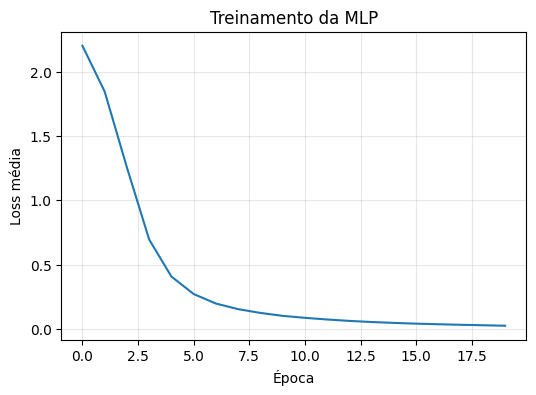

In [194]:
torch.manual_seed(SEED)
train_loader, test_loader = make_loaders(
    X_train_scaled, y_train, X_test_scaled, y_test, batch_size=64
)
mlp, history = train_pytorch_model(train_loader, epochs=20, lr=1e-3)

plt.figure(figsize=(6, 4))
plt.plot(history["loss"])
plt.xlabel("Época")
plt.ylabel("Loss média")
plt.title("Treinamento da MLP")
plt.grid(alpha=.3)
plt.show()

In [195]:
mlp_pred = predict_pytorch(mlp, test_loader)
logreg_metrics = compute_metrics(y_test, logreg_pred)
mlp_metrics = compute_metrics(y_test, mlp_pred)
print("Acurácia Logística:", logreg_metrics["accuracy"])
print("Acurácia MLP:", mlp_metrics["accuracy"])

Acurácia Logística: 0.9722222222222222
Acurácia MLP: 0.9666666666666667


Total de erros: 12
Confusões mais frequentes (real, previsto, quantidade): [(np.int64(8), np.int64(1), 3), (np.int64(1), np.int64(8), 1), (np.int64(6), np.int64(8), 1)]


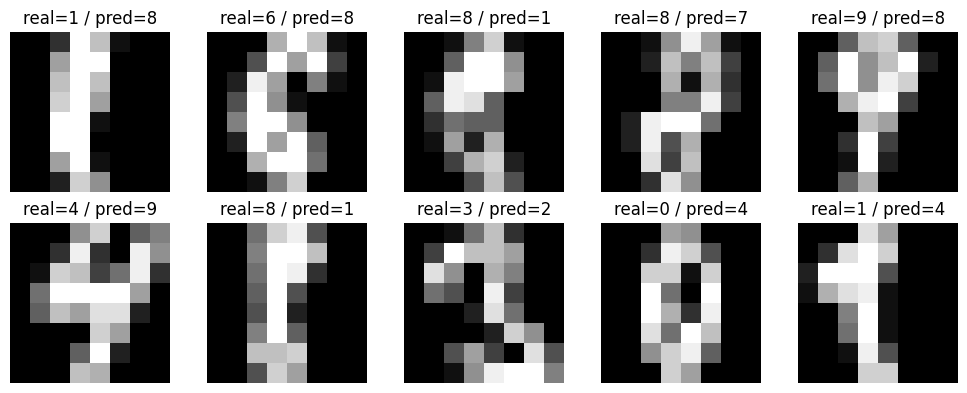

In [196]:
errors = analyze_errors(y_test, mlp_pred, top_k=3)
print("Total de erros:", len(errors["error_indices"]))
print("Confusões mais frequentes (real, previsto, quantidade):", errors["top_confusions"])

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), errors["error_indices"][:10]):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    ax.set_title(f"real={y_test[idx]} / pred={mlp_pred[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

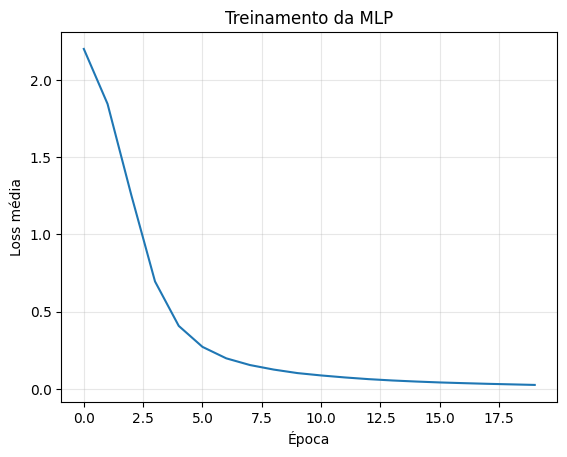

In [197]:
torch.manual_seed(SEED)
train_loader, test_loader = make_loaders(
    X_train_scaled, y_train, X_test_scaled, y_test, batch_size=64
)
mlp, history = train_pytorch_model(train_loader, epochs=20, lr=1e-3)
plt.plot(history["loss"])
plt.xlabel("Época"); plt.ylabel("Loss média"); plt.title("Treinamento da MLP"); plt.grid(alpha=.3)

## Exercício 7 — Predição e métricas

Implemente predição em modo de avaliação, sem gradientes. Depois retorne acurácia e matriz de confusão 10×10.

In [198]:
def predict_pytorch(model, data_loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for batch_x, _ in data_loader:
            outputs = model(batch_x)
            _, predicted = torch.max(outputs, 1)
            preds.extend(predicted.numpy())
    return np.array(preds)


def compute_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": float(acc), "confusion_matrix": cm}

In [199]:
mlp_pred = predict_pytorch(mlp, test_loader)
logreg_metrics = compute_metrics(y_test, logreg_pred)
mlp_metrics = compute_metrics(y_test, mlp_pred)
print("Logística:", logreg_metrics["accuracy"])
print("MLP:", mlp_metrics["accuracy"])

Logística: 0.9722222222222222
MLP: 0.9666666666666667


## Exercício 8 — Análise de erro

Retorne os índices errados, os pares `(verdadeiro, previsto)` e os três pares de confusão mais frequentes. Em um par de confusão, a ordem importa; exclua a diagonal.

In [200]:
def analyze_errors(y_true, y_pred, top_k=3):
    # Encontra os índices onde a predição foi incorreta
    error_indices = np.where(y_true != y_pred)[0]

    # Coleta os pares de erro (real, predito)
    error_pairs = [(y_true[idx], y_pred[idx]) for idx in error_indices]

    # Conta a frequência de cada par de confusão
    from collections import Counter
    counts = Counter(error_pairs)

    # Seleciona os top_k pares mais comuns
    # Cada elemento em counts.most_common(top_k) é no formato ((real, previsto), frequencia)
    # Queremos o formato (real, previsto, frequencia)
    top_confusions = [(pair[0], pair[1], freq) for pair, freq in counts.most_common(top_k)]

    return {
        "error_indices": error_indices.tolist(),
        "error_pairs": error_pairs,
        "top_confusions": top_confusions
    }

Total de erros: 12
Confusões mais frequentes (real, previsto, quantidade): [(np.int64(8), np.int64(1), 3), (np.int64(1), np.int64(8), 1), (np.int64(6), np.int64(8), 1)]


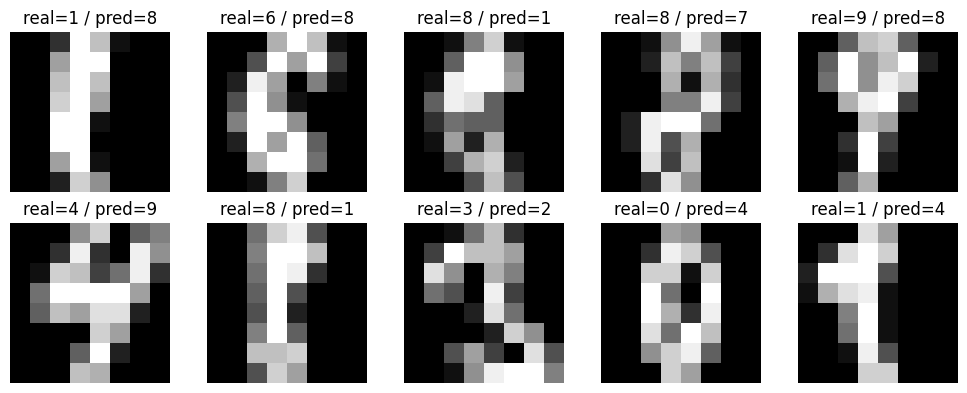

In [201]:
errors = analyze_errors(y_test, mlp_pred, top_k=3)
print("Total de erros:", len(errors["error_indices"]))
print("Confusões mais frequentes (real, previsto, quantidade):", errors["top_confusions"])

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), errors["error_indices"][:10]):
    ax.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    ax.set_title(f"real={y_test[idx]} / pred={mlp_pred[idx]}")
    ax.axis("off")
plt.tight_layout()

## Opcional

Explore outras configurações da MLP, otimizadores e learning_rate. Verifique se você consegue obter um modelo de maior acurácia ou que consegue ser treinado em menos iterações.

### Exploração de Hiperparâmetros (Seção Opcional)
Vamos testar diferentes variações de arquitetura da MLP, otimizadores e taxas de aprendizado para comparar o desempenho final na partição de teste.

In [202]:
class CustomMLP(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()
        layers = []
        in_dim = 64
        for h_dim in hidden_sizes:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

def experiment(hidden_sizes, opt_name, lr, epochs=25):
    torch.manual_seed(SEED)
    model = CustomMLP(hidden_sizes)
    criterion = nn.CrossEntropyLoss()

    if opt_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    for epoch in range(epochs):
        model.train()
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

    preds = predict_pytorch(model, test_loader)
    acc = compute_metrics(y_test, preds)["accuracy"]
    return acc

# Definição do grid de busca
experiments_grid = [
    {"hidden": [64, 32], "opt": "Adam", "lr": 1e-3},
    {"hidden": [128, 64, 32], "opt": "Adam", "lr": 1e-3},
    {"hidden": [128, 64, 32], "opt": "Adam", "lr": 3e-3},
    {"hidden": [64, 32], "opt": "SGD", "lr": 1e-2},
    {"hidden": [128, 64], "opt": "Adam", "lr": 1e-3}
]

print("Iniciando experimentos...")
for i, config in enumerate(experiments_grid):
    acc = experiment(config["hidden"], config["opt"], config["lr"])
    print(f"Experimento {i+1}: Arquitetura={config['hidden']}, Otimizador={config['opt']}, LR={config['lr']} -> Acurácia no Teste: {acc:.4f}")

Iniciando experimentos...
Experimento 1: Arquitetura=[64, 32], Otimizador=Adam, LR=0.001 -> Acurácia no Teste: 0.9667
Experimento 2: Arquitetura=[128, 64, 32], Otimizador=Adam, LR=0.001 -> Acurácia no Teste: 0.9694
Experimento 3: Arquitetura=[128, 64, 32], Otimizador=Adam, LR=0.003 -> Acurácia no Teste: 0.9694
Experimento 4: Arquitetura=[64, 32], Otimizador=SGD, LR=0.01 -> Acurácia no Teste: 0.9667
Experimento 5: Arquitetura=[128, 64], Otimizador=Adam, LR=0.001 -> Acurácia no Teste: 0.9806


### Criação de um Gatinho em Matriz de Pixels (Exploração Criativa)
Criaremos uma matriz 12x12 representando a imagem digital de um gato e a visualizaremos no mesmo formato do nosso dataset.

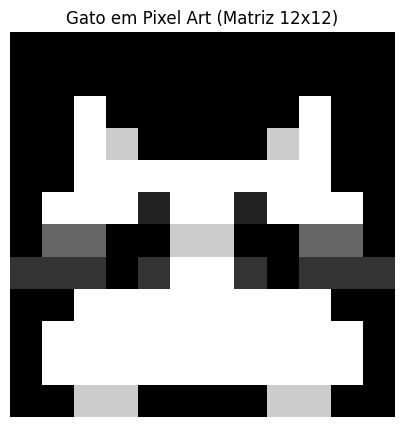

In [203]:
# Criando uma matriz de pixels vazia (fundo escuro)
gato = np.zeros((12, 12))

# Orelhas
gato[2, 2] = 15; gato[2, 9] = 15
gato[3, 2] = 15; gato[3, 3] = 12; gato[3, 8] = 12; gato[3, 9] = 15

# Cabeça / Rosto
gato[4, 2:10] = 15
gato[5, 1:11] = 15

# Olhos (com pupilas verticais ou vazias)
gato[5, 4] = 2; gato[5, 7] = 2

# Nariz e Boca
gato[6, 5:7] = 12
gato[7, 4] = 3; gato[7, 7] = 3
gato[7, 5:7] = 15

# Bochechas / Bigodes
gato[6, 1:3] = 6; gato[6, 9:11] = 6
gato[7, 0:3] = 3; gato[7, 9:12] = 3

# Corpo / Ombros
gato[8, 2:10] = 15
gato[9, 1:11] = 15
gato[10, 1:11] = 15

# Patas
gato[11, 2:4] = 12; gato[11, 8:10] = 12

# Exibindo a nossa obra de arte pixelada
plt.figure(figsize=(5, 5))
plt.imshow(gato, cmap="gray", interpolation="nearest")
plt.title("Gato em Pixel Art (Matriz 12x12)")
plt.axis("off")
plt.show()